# **SO SÁNH CÁC MODLE TRÊN TẬP MNIST**

Đánh giá toàn diện các mô hình học máy và học sâu đã được thực nghiệm qua 4 notebook chuyên đề:
* `1_Bayes`: Mô hình phân loại xác suất Naïve Bayes đa thức (`MultinomialNB-NP`).
* `2_Logistic`: Mô hình phân loại tuyến tính Hồi quy Logistic (`LogisticRegression-NP`).
* `3_MLP_CNN`: Mạng nơ-ron nhân tạo đa tầng (`MLP`) và Mạng nơ-ron tích chập (`CNN`).
* `4_Ensemble`: Phương pháp học kết hợp Boosting (`AdaBoost` với các bộ học cơ sở khác nhau).

Toàn bộ dữ liệu đánh giá được trích xuất trực tiếp từ các tệp kết quả chuẩn hóa trong thư mục `results/`, tập trung vào tập kiểm thử độc lập (Test Set) gồm 10.000 mẫu ảnh để đảm bảo tính khách quan và khả năng tổng quát hóa.



## **1. Giải thích các params tối ưu**

Trong phần này, kết quả của từng notebook được nạp riêng biệt. Với mỗi phương pháp, chúng ta trích xuất cấu hình siêu tham số tối ưu (`params`) trên tập kiểm thử, phân tích bản chất cơ chế hoạt động, ý nghĩa toán học và tác động thực tế của từng tham số đối với bài toán nhận dạng chữ số MNIST.


In [31]:
import os
import sys
import tempfile
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình thư mục tạm cho Matplotlib trên Windows
os.environ["MPLCONFIGDIR"] = tempfile.gettempdir()
warnings.filterwarnings("ignore")

In [32]:
# Xác định thư mục gốc dự án (PROJECT_ROOT)
PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "pyproject.toml").is_file() and (PROJECT_ROOT / "src" / "pattern_recognition" / "config.py").is_file()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (chứa pyproject.toml).")
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Thiết lập môi trường thành công.")
print(f"Thư mục kết quả (RESULTS_DIR): {RESULTS_DIR}")
print(f"Thư mục biểu đồ (FIGURES_DIR): {FIGURES_DIR}")


Thiết lập môi trường thành công.
Thư mục kết quả (RESULTS_DIR): C:\Users\Lenovo\Downloads\Pattern-Recognition\results
Thư mục biểu đồ (FIGURES_DIR): C:\Users\Lenovo\Downloads\Pattern-Recognition\figures


### **1.1. Khảo sát mô hình Naïve Bayes (từ notebook `1_Bayes`)**


In [33]:
# Đọc kết quả từ 1_Bayes_metrics.csv
bayes_path = RESULTS_DIR / "1_Bayes_metrics.csv"
df_bayes = pd.read_csv(bayes_path)

# Lọc kết quả trên tập kiểm thử (test)
test_bayes = df_bayes[df_bayes["split"] == "test"].copy()

print("=== KẾT QUẢ THỰC NGHIỆM TỪ NOTEBOOK 1_Bayes (TẬP TEST) ===")
for _, row in test_bayes.iterrows():
    print(f"Mô hình: {row['model']}")
    print(f"Cấu hình siêu tham số (params): {row['params']}")
    print(f"Độ chính xác (Accuracy): {row['accuracy']*100:.2f}%")
    print(f"Macro-F1 Score: {row['f1_macro']*100:.2f}%")
    print(f"Thời gian huấn luyện: {row['train_seconds']:.4f} giây")
    print(f"Thời gian dự đoán (10.000 mẫu): {row['predict_seconds']:.4f} giây")
    latency_us = (row['predict_seconds'] / row['n_samples']) * 1e6
    print(f"Độ trễ trung bình mỗi mẫu: {latency_us:.1f} micro-giây (µs)")


=== KẾT QUẢ THỰC NGHIỆM TỪ NOTEBOOK 1_Bayes (TẬP TEST) ===
Mô hình: MultinomialNB-NP
Cấu hình siêu tham số (params): alpha=0.0001
Độ chính xác (Accuracy): 83.56%
Macro-F1 Score: 83.41%
Thời gian huấn luyện: 0.0595 giây
Thời gian dự đoán (10.000 mẫu): 0.3330 giây
Độ trễ trung bình mỗi mẫu: 33.3 micro-giây (µs)


#### **Giải thích chi tiết siêu tham số và cơ chế hoạt động của `MultinomialNB-NP`**

* **Bản chất mô hình:** Mô hình Naïve Bayes đa thức (`MultinomialNB-NP`) được xây dựng từ đầu bằng NumPy, dựa trên nguyên lý xác suất Bayes kết hợp với giả định độc lập có điều kiện giữa các điểm ảnh khi biết trước nhãn lớp:
  $$P(x | y = c) = \prod_{i=1}^{784} P(x_i | y = c)$$
* **Ý nghĩa siêu tham số `alpha = 0.0001` (Hệ số làm trơn Laplace):**
  Trong công thức ước lượng tần suất xuất hiện của điểm ảnh thứ $i$ trong lớp chữ số $c$:
  $$P(x_i | y = c) = \frac{N_{ci} + \alpha}{N_c + \alpha \cdot D}$$
  trong đó $N_{ci}$ là tổng giá trị độ sáng của điểm ảnh $i$ thuộc các ảnh lớp $c$, $N_c$ là tổng độ sáng của toàn bộ điểm ảnh trong lớp $c$, và $D = 784$ là số lượng đặc trưng.
  * Nếu một điểm ảnh chưa từng xuất hiện nét vẽ nào trong tập huấn luyện của một lớp chữ số (ví dụ các điểm ảnh ở góc viền ảnh), giá trị đếm $N_{ci} = 0$. Không có hệ số làm trơn, xác suất $P(x_i | y = c) = 0$, kéo theo tích xác suất của toàn bộ bức ảnh $P(x | y = c)$ bị triệt tiêu về 0, dẫn đến sai lệch nghiêm trọng khi dự đoán.
  * Việc lựa chọn giá trị $\alpha = 0.0001$ cực nhỏ (thay vì giá trị mặc định $\alpha = 1.0$) mang ý nghĩa thực tiễn quan trọng: dữ liệu ảnh MNIST có phần lớn điểm ảnh là nền đen ($x_i = 0$). Nếu cộng thêm $\alpha = 1.0$, xác suất của các điểm ảnh nền sẽ bị thổi phồng, làm phẳng phân phối tần suất và làm mờ nhạt sự khác biệt giữa nét vẽ và nền ảnh. Hệ số $\alpha = 0.0001$ đóng vai trò một ngưỡng an toàn số học cực nhỏ để tránh lỗi nhân với 0, đồng thời bảo toàn độ tương phản thực tế của nét chữ.
* **Nguyên nhân giới hạn độ chính xác (83.56%):**
  Giả định các điểm ảnh độc lập có điều kiện là hoàn toàn phi thực tế đối với dữ liệu thị giác. Một nét chữ số được hình thành từ chuỗi các điểm ảnh liền kề có tương quan không gian rất cao. Việc bỏ qua mối liên hệ giữa các điểm ảnh lân cận khiến Naïve Bayes không thể nắm bắt được hình thái học của nét chữ, dẫn đến độ chính xác dừng lại ở mức thấp nhất trong các mô hình đơn lẻ.


---
### **1.2. Khảo sát mô hình Hồi quy Logistic (từ notebook `2_Logistic`)**


In [34]:
# Đọc kết quả từ 2_Logistic_metrics.csv
logistic_path = RESULTS_DIR / "2_Logistic_metrics.csv"
df_logistic = pd.read_csv(logistic_path)

# Lọc kết quả trên tập kiểm thử (test)
test_logistic = df_logistic[df_logistic["split"] == "test"].copy()

print("=== KẾT QUẢ THỰC NGHIỆM TỪ NOTEBOOK 2_Logistic (TẬP TEST) ===")
for _, row in test_logistic.iterrows():
    print(f"Mô hình: {row['model']}")
    print(f"Cấu hình siêu tham số (params): {row['params']}")
    print(f"Độ chính xác (Accuracy): {row['accuracy']*100:.2f}%")
    print(f"Macro-F1 Score: {row['f1_macro']*100:.2f}%")
    print(f"Thời gian huấn luyện: {row['train_seconds']:.4f} giây")
    print(f"Thời gian dự đoán (10.000 mẫu): {row['predict_seconds']:.4f} giây")
    latency_us = (row['predict_seconds'] / row['n_samples']) * 1e6
    print(f"Độ trễ trung bình mỗi mẫu: {latency_us:.1f} micro-giây (µs)")


=== KẾT QUẢ THỰC NGHIỆM TỪ NOTEBOOK 2_Logistic (TẬP TEST) ===
Mô hình: LogisticRegression-NP
Cấu hình siêu tham số (params): eta=1.0,max_epochs=100,lam=1e-4,strategy=OneVsRest
Độ chính xác (Accuracy): 90.18%
Macro-F1 Score: 90.03%
Thời gian huấn luyện: 32.2878 giây
Thời gian dự đoán (10.000 mẫu): 0.0259 giây
Độ trễ trung bình mỗi mẫu: 2.6 micro-giây (µs)


#### **Giải thích chi tiết siêu tham số và cơ chế hoạt động của `LogisticRegression-NP`**

* **Bản chất mô hình:** Mô hình Hồi quy Logistic đa lớp (`LogisticRegression-NP`) được cài đặt bằng NumPy thuần, tối ưu hóa hàm mất mát Cross-Entropy nhị phân kết hợp số hạng điều chuẩn L2 bằng giải thuật Gradient Descent.
* **Ý nghĩa từng siêu tham số đã tinh chỉnh:**
  * `eta = 1.0` (Tốc độ học $\eta$): Trong thuật toán Gradient Descent, độ dốc được tính trung bình trên toàn bộ mẫu dữ liệu (chia cho $N = 50.000$). Khi gradient đã được chuẩn hóa theo kích thước mẫu và dữ liệu đầu vào đã được co giãn về đoạn $[0, 1]$, độ lớn bước cập nhật tỉ lệ thuận với $\eta$. Giá trị $\eta = 1.0$ cho phép các trọng số di chuyển đủ nhanh về phía cực tiểu mà không bị dao động phân kỳ hay rơi vào bế tắc tại các vùng có độ dốc phẳng.
  * `max_epochs = 100`: Số chu kỳ lặp tối đa qua toàn bộ tập dữ liệu huấn luyện. Sau 100 epoch, hàm mất mát Log-loss đã tiệm cận giá trị bão hòa, chuẩn độ dốc $\|\nabla_w \mathcal{L}\|$ giảm xuống mức rất nhỏ, đảm bảo mô hình đã hội tụ hoàn toàn.
  * `lam = 1e-4` (Hệ số điều chuẩn L2 $\lambda$): Bổ sung hàm phạt $\frac{\lambda}{2} \|w\|^2$ vào hàm mục tiêu tối ưu. Hệ số phạt $\lambda = 10^{-4}$ có độ lớn vừa đủ để kiềm chế các trọng số ứng với các điểm ảnh biên (nơi ít chứa nét chữ) không bị tăng vọt ngẫu nhiên do nhiễu, hạn chế tình trạng quá khớp (overfitting) mà vẫn đảm bảo độ sắc nét của ranh giới quyết định.
  * `strategy = OneVsRest` (Chiến lược Một đấu Tất cả): Chia bài toán phân loại 10 lớp thành 10 bộ phân loại nhị phân độc lập. Với mỗi chữ số $k \in \{0, 1, \dots, 9\}$, mô hình học một vector trọng số $w_k \in \mathbb{R}^{784}$ và độ lệch $b_k \in \mathbb{R}$ để phân biệt chữ số $k$ với 9 chữ số còn lại. Nhãn dự đoán cuối cùng là lớp có giá trị xác suất sigmoid cao nhất:
    $$\hat{y} = \arg\max_{k \in \{0, \dots, 9\}} \sigma(w_k^T x + b_k)$$
* **Đánh giá hiệu năng thực tế (90.18%):**
  Hồi quy Logistic tạo ra 10 siêu phẳng tuyến tính trong không gian 784 chiều. Mô hình vượt trội hơn hẳn Naïve Bayes (tăng 6.62% độ chính xác) nhờ khả năng gán trọng số dương cho các điểm ảnh đặc trưng của nét vẽ và trọng số âm cho các vùng khoảng trống. Tuy nhiên, do bản chất tuyến tính, mô hình không thể biểu diễn được các đường cong khép kín hay mối quan hệ phi tuyến phức tạp giữa các nét chữ (ví dụ phân biệt số 3 với số 5, số 4 với số 9).


---
### **1.3. Khảo sát mô hình Mạng Nơ-ron Nhân tạo và Mạng Tích chập (từ notebook `3_MLP_CNN`)**


In [35]:
# Đọc kết quả từ 3_MLP_CNN_metrics.csv
mlp_cnn_path = RESULTS_DIR / "3_MLP_CNN_metrics.csv"
df_mlp_cnn = pd.read_csv(mlp_cnn_path)

# Lọc kết quả trên tập kiểm thử (test)
test_mlp_cnn = df_mlp_cnn[df_mlp_cnn["split"] == "test"].copy()

print("=== KẾT QUẢ THỰC NGHIỆM TỪ NOTEBOOK 3_MLP_CNN (TẬP TEST) ===")
for _, row in test_mlp_cnn.iterrows():
    print(f"Mô hình: {row['model']}")
    print(f"Cấu hình siêu tham số (params): {row['params']}")
    print(f"Độ chính xác (Accuracy): {row['accuracy']*100:.2f}%")
    print(f"Macro-F1 Score: {row['f1_macro']*100:.2f}%")
    print(f"Thời gian huấn luyện: {row['train_seconds']:.4f} giây")
    print(f"Thời gian dự đoán (10.000 mẫu): {row['predict_seconds']:.4f} giây")
    latency_us = (row['predict_seconds'] / row['n_samples']) * 1e6
    print(f"Độ trễ trung bình mỗi mẫu: {latency_us:.1f} micro-giây (µs)")
    print()


=== KẾT QUẢ THỰC NGHIỆM TỪ NOTEBOOK 3_MLP_CNN (TẬP TEST) ===
Mô hình: MLP
Cấu hình siêu tham số (params): arch=784-256-128-10,activation=ReLU,init=He,lr=0.1,momentum=0.5,batch=64,weight_decay=1e-4,best_epoch=18
Độ chính xác (Accuracy): 98.26%
Macro-F1 Score: 98.25%
Thời gian huấn luyện: 38.3577 giây
Thời gian dự đoán (10.000 mẫu): 0.0246 giây
Độ trễ trung bình mỗi mẫu: 2.5 micro-giây (µs)

Mô hình: CNN
Cấu hình siêu tham số (params): conv=32x4x4,pool=2x2,dense=128,optimizer=Adam,lr=1e-3,batch=128,max_epochs=10,patience=2,best_epoch=7
Độ chính xác (Accuracy): 98.76%
Macro-F1 Score: 98.76%
Thời gian huấn luyện: 56.8950 giây
Thời gian dự đoán (10.000 mẫu): 0.5319 giây
Độ trễ trung bình mỗi mẫu: 53.2 micro-giây (µs)



#### **Giải thích chi tiết siêu tham số và cơ chế hoạt động của `MLP` và `CNN`**

Hai mô hình học sâu đại diện cho hai hướng tiếp cận biểu diễn đặc trưng phi tuyến tính:

**1. Mạng nơ-ron đa tầng (MLP - Multi-Layer Perceptron):**
* `arch = 784-256-128-10`: Kiến trúc mạng truyền thẳng gồm 2 tầng ẩn. Tầng ẩn 1 (256 nơ-ron) thực hiện phép co giãn và biến đổi phi tuyến từ 784 điểm ảnh đầu vào; tầng ẩn 2 (128 nơ-ron) tiếp tục tổng hợp các tổ hợp đặc trưng bậc cao trước khi đưa vào tầng đầu ra 10 nơ-ron (phân loại đa lớp bằng Softmax). Kiến trúc này tạo ra sự cân bằng hoàn hảo giữa sức chứa biểu diễn (capacity) và chi phí tham số.
* `activation = ReLU`: Hàm kích hoạt chỉnh lưu $f(z) = \max(0, z)$. Đạo hàm của ReLU luôn bằng 1 ở miền dương, giúp giải quyết triệt để hiện tượng suy giảm gradient (vanishing gradient) thường gặp ở các hàm bão hòa như Sigmoid hay Tanh, cho phép tín hiệu đạo hàm truyền ngược hiệu quả qua các tầng mạng.
* `init = He` (Khởi tạo He Normal): Các trọng số được khởi tạo ngẫu nhiên từ phân phối $\mathcal{N}(0, 2/n_{in})$. Đây là phương pháp khởi tạo được thiết kế tối ưu toán học cho hàm ReLU, giúp bảo toàn phương sai của tín hiệu kích hoạt qua từng tầng, ngăn chặn tình trạng tín hiệu bị triệt tiêu hoặc bùng nổ ngay từ epoch đầu tiên.
* `lr = 0.1, momentum = 0.5, batch = 64`: Thuật toán Mini-batch SGD với tốc độ học 0.1 cập nhật trọng số theo từng lô 64 ảnh. Hệ số quán tính (momentum) 0.5 giúp tích lũy động lượng từ các bước gradient trước đó, đẩy nhanh tốc độ di chuyển dọc theo các rãnh dốc và vượt qua các điểm yên ngựa (saddle points) trong không gian tham số.
* `weight_decay = 1e-4, best_epoch = 18`: Hệ số suy giảm trọng số L2 kiềm chế độ lớn tham số. Cơ chế Dừng sớm (Early Stopping) với `patience = 4` đã tự động ngắt quá trình huấn luyện ở epoch 18 (trên tối đa 20 epoch) khi mất mát trên tập kiểm định đạt giá trị tối ưu, giúp mô hình đạt độ chính xác **98.26%** mà không bị quá khớp.

**2. Mạng nơ-ron tích chập (CNN - Convolutional Neural Network):**
* `conv = 32x4x4`: Tầng tích chập đầu tiên sử dụng 32 bộ lọc kích thước $4 \times 4$. Thay vì duỗi phẳng ảnh thành vector 1D như MLP, các bộ lọc tích chập trượt trực tiếp trên ma trận 2D ($28 \times 28$) của ảnh. Cơ chế chia sẻ trọng số (weight sharing) và trường thụ nhận cục bộ (local receptive field) giúp trích xuất các đặc trưng không gian cơ bản như cạnh ngang, nét xiên, góc lượn và độ cong.
* `pool = 2x2`: Tầng gộp cực đại (Max Pooling) kích thước $2 \times 2$ với bước trượt 2, làm giảm kích thước bản đồ đặc trưng từ $28 \times 28$ xuống $14 \times 14$. Thao tác này vừa giảm 75% khối lượng tính toán ở tầng tiếp theo, vừa tạo ra tính bất biến đối với các phép dịch chuyển nhỏ (translation invariance) của nét chữ.
* `dense = 128`: Tầng kết nối toàn phần với 128 nơ-ron tổng hợp toàn bộ thông tin không gian thành vector đặc trưng cô đọng trước khi đưa ra 10 lớp đầu ra.
* `optimizer = Adam, lr = 1e-3, batch = 128`: Trình tối ưu hóa thích nghi Adam tự động điều chỉnh tốc độ học cho từng tham số riêng biệt thông qua ước lượng moment bậc 1 và moment bậc 2 của gradient, kết hợp với kích thước lô 128 giúp việc huấn luyện diễn ra cực kỳ ổn định.
* `best_epoch = 7`: Mô hình đạt điểm cực đại trên tập kiểm định chỉ sau 7 epoch (trên tối đa 10 epoch), đạt độ chính xác dẫn đầu tuyệt đối **98.76%** trên tập test.


---
### **1.4. Khảo sát phương pháp Học kết hợp Boosting (từ notebook `4_Ensemble`)**


In [36]:
# Đọc kết quả từ 4_Ensemble_metrics.csv
ensemble_path = RESULTS_DIR / "4_Ensemble_metrics.csv"
df_ensemble = pd.read_csv(ensemble_path)

# Lọc kết quả trên tập kiểm thử (test)
test_ensemble = df_ensemble[df_ensemble["split"] == "test"].copy()

print("=== KẾT QUẢ THỰC NGHIỆM TỪ NOTEBOOK 4_Ensemble (TẬP TEST) ===")
for _, row in test_ensemble.iterrows():
    print(f"Mô hình: {row['model']}")
    print(f"Cấu hình siêu tham số (params): {row['params']}")
    print(f"Độ chính xác (Accuracy): {row['accuracy']*100:.2f}%")
    print(f"Macro-F1 Score: {row['f1_macro']*100:.2f}%")
    print(f"Thời gian huấn luyện: {row['train_seconds']:.2f} giây")
    print(f"Thời gian dự đoán (10.000 mẫu): {row['predict_seconds']:.4f} giây")
    latency_us = (row['predict_seconds'] / row['n_samples']) * 1e6
    print(f"Độ trễ trung bình mỗi mẫu: {latency_us:.1f} micro-giây (µs)")
    print("-" * 50)


=== KẾT QUẢ THỰC NGHIỆM TỪ NOTEBOOK 4_Ensemble (TẬP TEST) ===
Mô hình: AdaBoost (depth=3)
Cấu hình siêu tham số (params): n_estimators=200,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=3)
Độ chính xác (Accuracy): 91.75%
Macro-F1 Score: 91.70%
Thời gian huấn luyện: 11019.24 giây
Thời gian dự đoán (10.000 mẫu): 2.6681 giây
Độ trễ trung bình mỗi mẫu: 266.8 micro-giây (µs)
--------------------------------------------------
Mô hình: AdaBoost (LogReg)
Cấu hình siêu tham số (params): n_estimators=50,learning_rate=0.5,estimator=LogisticRegression(max_iter=500)
Độ chính xác (Accuracy): 85.06%
Macro-F1 Score: 84.85%
Thời gian huấn luyện: 48.39 giây
Thời gian dự đoán (10.000 mẫu): 0.3013 giây
Độ trễ trung bình mỗi mẫu: 30.1 micro-giây (µs)
--------------------------------------------------
Mô hình: AdaBoost (stump)
Cấu hình siêu tham số (params): n_estimators=100,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=1)
Độ chính xác (Accuracy): 78.53%
Macro-F1 Score: 78.37%
T

#### **Giải thích chi tiết siêu tham số và cơ chế hoạt động của các biến thể `AdaBoost`**

Phương pháp Boosting hoạt động theo nguyên lý kết hợp tuần tự một chuỗi các bộ học yếu (weak learners). Sau mỗi vòng lặp, trọng số của các mẫu dữ liệu bị phân loại sai được tăng lên, buộc bộ học tiếp theo phải tập trung xử lý các trường hợp khó:

* **AdaBoost (depth=3):**
  * `n_estimators = 200, learning_rate = 0.5, estimator = DecisionTreeClassifier(max_depth=3)`.
  * Cây quyết định độ sâu 3 có tối đa $2^3 = 8$ nút lá, có khả năng phân đoạn không gian và nắm bắt được các tương tác phi tuyến bậc thấp giữa một vài điểm ảnh lân cận.
  * Tốc độ học $\eta = 0.5$ thu nhỏ sự đóng góp của từng cây để tránh tình trạng thuật toán quá tập trung vào các mẫu nhiễu.
  * Kết quả: Đạt độ chính xác **91.75%**, cao nhất trong các mô hình học máy truyền thống không dùng mạng nơ-ron. Tuy nhiên, thời gian huấn luyện lên tới **11.019.24 giây** (khoảng **3.06 giờ**). Nguyên nhân là thuật toán AdaBoost mang tính tuần tự tuyệt đối (cây thứ $t$ chỉ được xây dựng khi cây thứ $t-1$ đã hoàn tất), và ở mỗi vòng lặp thuật toán phải quét qua toàn bộ 50.000 ảnh 784 chiều để tìm điểm phân chia tối ưu.
* **AdaBoost (LogReg):**
  * `n_estimators = 50, learning_rate = 0.5, estimator = LogisticRegression(max_iter=500)`.
  * Kết hợp 50 bộ phân loại hồi quy Logistic tuyến tính. Độ chính xác chỉ đạt **85.06%**, sụt giảm tới 5.12% so với mô hình Logistic đơn lẻ (90.18%).
  * Bản chất toán học: Bộ học cơ sở trong AdaBoost cần có độ biến thiên cao (high variance) để phản ứng linh hoạt với sự thay đổi trọng số của mẫu. Hồi quy Logistic là mô hình tuyến tính toàn cục có độ chệch lớn (high bias) và tính ổn định cao. Khi dữ liệu bị gán trọng số cực đoan ở các điểm biên khó phân loại, ranh giới tuyến tính bị xoay lệch nghiêm trọng, làm hỏng khả năng phân loại trên các vùng dữ liệu thông thường.
* **AdaBoost (stump):**
  * `n_estimators = 100, learning_rate = 0.5, estimator = DecisionTreeClassifier(max_depth=1)`.
  * Mỗi gốc cây quyết định (Decision Stump) chỉ có duy nhất 1 điểm phân chia dựa trên 1 điểm ảnh đơn lẻ. Không gian chữ số MNIST có 10 lớp và 784 chiều, một nhát cắt đơn trục mang tính cục bộ quá yếu để tạo nên ranh giới phân biệt hiệu quả, do đó mô hình chỉ đạt độ chính xác **78.53%** dù đã kết hợp 100 cây.
* **AdaBoost (GaussianNB):**
  * `n_estimators = 50, learning_rate = 0.5, estimator = GaussianNB()`.
  * Độ chính xác thấp nhất toàn bộ nghiên cứu: **56.41%**, kèm theo thời gian dự đoán chậm (7.84 giây cho 10.000 mẫu).
  * Nguyên nhân: Phân phối chuẩn liên tục $\mathcal{N}(\mu, \sigma^2)$ hoàn toàn xung đột với dữ liệu ảnh MNIST (phần lớn điểm ảnh là 0 hoặc 1). Khi áp dụng trọng số mẫu của AdaBoost, việc ước lượng kỳ vọng và phương sai có trọng số bị méo mó nghiêm trọng, khiến mô hình bị suy thoái hoàn toàn.


### **1.5. Công bằng trong thực nghiệm so sánh các mô hình**

Khi so sánh Logistic Regression, MLP, CNN và AdaBoost, số epoch hoặc số vòng lặp huấn luyện không nhất thiết phải bằng nhau. Các thuật toán có cơ chế học, cách cập nhật tham số và chi phí tính toán khác nhau; vì vậy, số epoch riêng lẻ không phải là thước đo đủ để kết luận mô hình nào được huấn luyện nhiều hơn.

#### **1. Số epoch không tương đương với số lần cập nhật tham số**

Với Logistic Regression sử dụng Full-batch Gradient Descent, mỗi epoch thường thực hiện một lần cập nhật tham số dựa trên toàn bộ tập huấn luyện. Do đó, 100 epoch tương ứng khoảng **100 lần cập nhật**.

MLP và CNN sử dụng Mini-batch SGD. Nếu tập huấn luyện có 50.000 ảnh và không loại bỏ batch cuối:

- MLP với batch size 64 thực hiện $\lceil 50.000/64 \rceil = 782$ lần cập nhật mỗi epoch. Sau 18 epoch là khoảng **14.076 lần cập nhật**.
- CNN với batch size 128 thực hiện $\lceil 50.000/128 \rceil = 391$ lần cập nhật mỗi epoch. Sau 7 epoch là khoảng **2.737 lần cập nhật**.

Các con số này cho thấy không thể chỉ nhìn vào số epoch để so sánh cường độ huấn luyện giữa các mô hình. Tuy nhiên, số lần cập nhật cũng **không hoàn toàn tương đương về chi phí hoặc hiệu quả**: mỗi cập nhật có lượng tính toán khác nhau, và thuật toán, kích thước mô hình, phần cứng cũng ảnh hưởng đáng kể.

#### **2. Early stopping**

MLP và CNN có dùng *early stopping* để theo dõi loss trên tập validation.

Cơ chế này nhằm hạn chế việc tiếp tục tối ưu trên tập train trong khi khả năng tổng quát hóa trên dữ liệu chưa thấy không còn cải thiện. Vì vậy, số epoch 18 của MLP hay 7 của CNN được hiểu là kết quả của **quy tắc dừng và cấu hình huấn luyện đã chọn**, chứ không tự nó chứng minh rằng đó là số epoch tối ưu tuyệt đối. 

#### **3. Số vòng lặp của AdaBoost có ý nghĩa khác**

AdaBoost xây dựng các weak learner theo trình tự: mỗi learner tiếp theo được huấn luyện với trọng số mẫu đã điều chỉnh dựa trên kết quả của các vòng trước. Vì vậy, 200 vòng lặp tương ứng với việc xây dựng tối đa **200 weak learner**, chứ không tương đương trực tiếp với 200 epoch của Logistic Regression hay 200 bước cập nhật của mạng nơ-ron.

Thời gian huấn luyện AdaBoost phụ thuộc vào loại weak learner, số mẫu, số đặc trưng và số vòng lặp. Do cách huấn luyện tuần tự, các vòng boosting không thể thực hiện độc lập hoàn toàn như những phép tính có thể song song hóa. Vì thế, khi so sánh, nên xem xét cả chất lượng dự đoán và chi phí tính toán, thay vì chỉ đối chiếu số vòng lặp.

#### **4. Điều kiện để phép so sánh có ý nghĩa**

Các mô hình không cần có cùng số epoch, nhưng cần được đánh giá theo một quy trình nhất quán: dùng cùng cách chia dữ liệu, cùng tập kiểm định và tập kiểm tra, cùng tiền xử lý phù hợp, và cùng các chỉ số đánh giá. Siêu tham số nên được chọn bằng dữ liệu huấn luyện/validation; tập test chỉ nên dùng để đánh giá cuối cùng, tránh dùng nó để điều chỉnh mô hình.

Nếu mục tiêu là so sánh hiệu quả dự đoán, có thể đối chiếu Accuracy, Macro F1 và các chỉ số liên quan trên cùng tập test. Nếu muốn so sánh cả hiệu quả tính toán, nên báo cáo thêm thời gian huấn luyện, thời gian suy luận hoặc ngân sách tính toán, đồng thời ghi rõ phần cứng và cấu hình chạy.

**Tóm lại**, số epoch khác nhau không tự động khiến phép so sánh thiếu công bằng, vì mỗi mô hình học theo cơ chế khác nhau. Tính công bằng phụ thuộc chủ yếu vào quy trình đánh giá nhất quán, cách lựa chọn siêu tham số minh bạch và việc báo cáo đủ cả chất lượng dự đoán lẫn chi phí tính toán khi cần.

---
## **2.Xuất `overall_comparison_metrics.csv` và So sánh tổng thể**

Toàn bộ các tệp kết quả riêng lẻ được hợp nhất thành file duy nhất và xuất bản ra tệp `results/overall_comparison_metrics.csv`. Sau đó, chúng ta xây dựng bảng tổng hợp xếp hạng tất cả các mô hình trên tập kiểm thử độc lập (Test Set, 10.000 mẫu) theo thứ tự độ chính xác giảm dần.


In [37]:
# Hợp nhất dữ liệu từ 4 file CSV
df_all = pd.concat([df_bayes, df_logistic, df_mlp_cnn, df_ensemble], ignore_index=True)

# Xuất tệp dữ liệu tổng hợp
output_metrics_file = RESULTS_DIR / "overall_comparison_metrics.csv"
df_all.to_csv(output_metrics_file, index=False)

print(f"Đã hợp nhất thành công {len(df_all)} dòng dữ liệu từ 4 notebook.")
print(f"Đã lưu tệp tổng hợp tại: {output_metrics_file}")


Đã hợp nhất thành công 24 dòng dữ liệu từ 4 notebook.
Đã lưu tệp tổng hợp tại: C:\Users\Lenovo\Downloads\Pattern-Recognition\results\overall_comparison_metrics.csv


In [38]:
# Lọc tập kiểm thử (test set) và sắp xếp theo Accuracy giảm dần
test_df = df_all[df_all["split"] == "test"].copy()
test_df = test_df.sort_values("accuracy", ascending=False).reset_index(drop=True)

# Hàm xác định notebook nguồn cho từng mô hình
def get_source_notebook(model_name):
    if "MultinomialNB" in model_name:
        return "1_Bayes"
    elif "LogisticRegression" in model_name:
        return "2_Logistic"
    elif model_name in ["MLP", "CNN"]:
        return "3_MLP_CNN"
    else:
        return "4_Ensemble"

test_df["notebook_source"] = test_df["model"].apply(get_source_notebook)

# Xây dựng bảng hiển thị chuẩn mực
display_table = pd.DataFrame({
    "Notebook nguồn": test_df["notebook_source"],
    "Mô hình": test_df["model"],
    "Độ chính xác (Acc %)": test_df["accuracy"].apply(lambda x: f"{x*100:.2f}%"),
    "Macro-F1 (%)": test_df["f1_macro"].apply(lambda x: f"{x*100:.2f}%"),
    "Precision (%)": test_df["precision_macro"].apply(lambda x: f"{x*100:.2f}%"),
    "Recall (%)": test_df["recall_macro"].apply(lambda x: f"{x*100:.2f}%"),
    "Thời gian Train (s)": test_df["train_seconds"].apply(lambda x: f"{x:.2f}"),
    "Thời gian Test (s)": test_df["predict_seconds"].apply(lambda x: f"{x:.4f}"),
    "Độ trễ / mẫu (µs)": (test_df["predict_seconds"] / test_df["n_samples"] * 1e6).apply(lambda x: f"{x:5.1f}"),
    "Tham số cấu hình chính": test_df["params"]
})

print("=== Bảng so sánh kết quả trên tập Test (MNIST TEST SET: 10.000 MẪU) ===")
display(display_table)


=== Bảng so sánh kết quả trên tập Test (MNIST TEST SET: 10.000 MẪU) ===


,Notebook nguồn,Mô hình,Độ chính xác (Acc %),Macro-F1 (%),Precision (%),Recall (%),Thời gian Train (s),Thời gian Test (s),Độ trễ / mẫu (µs),Tham số cấu hình chính
0,3_MLP_CNN,CNN,98.76%,98.76%,98.77%,98.75%,56.90,0.5319,53.2,"conv=32x4x4,pool=2x2,dense=128,optimizer=Adam,..."
1,3_MLP_CNN,MLP,98.26%,98.25%,98.25%,98.24%,38.36,0.0246,2.5,"arch=784-256-128-10,activation=ReLU,init=He,lr..."
2,4_Ensemble,AdaBoost (depth=3),91.75%,91.70%,91.81%,91.70%,11019.24,2.6681,266.8,"n_estimators=200,learning_rate=0.5,estimator=D..."
3,2_Logistic,LogisticRegression-NP,90.18%,90.03%,90.17%,90.03%,32.29,0.0259,2.6,"eta=1.0,max_epochs=100,lam=1e-4,strategy=OneVs..."
4,4_Ensemble,AdaBoost (LogReg),85.06%,84.85%,85.11%,84.79%,48.39,0.3013,30.1,"n_estimators=50,learning_rate=0.5,estimator=Lo..."
5,1_Bayes,MultinomialNB-NP,83.56%,83.41%,84.24%,83.25%,0.06,0.3330,33.3,alpha=0.0001
6,4_Ensemble,AdaBoost (stump),78.53%,78.37%,78.80%,78.26%,241.97,2.4197,242.0,"n_estimators=100,learning_rate=0.5,estimator=D..."
7,4_Ensemble,AdaBoost (GaussianNB),56.41%,50.83%,71.58%,55.63%,46.76,7.8411,784.1,"n_estimators=50,learning_rate=0.5,estimator=Ga..."


### **2.1. Phân tích kết quả thực nghiệm**

Dựa trên số liệu thực nghiệm được đo lường đồng nhất trên 10.000 mẫu ảnh kiểm thử, chúng ta rút ra các kết luận định lượng cốt lõi sau:

**1. Năng lực phân loại (Accuracy và Macro-F1):**
* **Nhóm dẫn đầu:**
  * `CNN` đạt vị trí quán quân với độ chính xác **98.76%** và Macro-F1 **98.76%**. Trên toàn bộ 10.000 ảnh kiểm thử, mô hình chỉ phân loại sai đúng 124 ảnh.
  * `MLP` bám sát ở vị trí thứ hai với độ chính xác **98.26%** và Macro-F1 **98.25%** (chỉ sai 174 ảnh). Khoảng cách chênh lệch 0.50% phản ánh giá trị vượt trội của các bộ lọc tích chập 2D trong việc nắm bắt cấu trúc hình học cục bộ và tính bất biến dịch chuyển so với việc kết nối toàn phần thuần túy.
* **Nhóm trung bình:**
  * `AdaBoost (depth=3)` đạt **91.75%** (Macro-F1: **91.70%**), đứng đầu trong các phương pháp học máy phi mạng nơ-ron. Cấu trúc cây độ sâu 3 đã phân đoạn không gian tốt hơn các mặt phẳng tuyến tính.
  * `LogisticRegression-NP` đạt **90.18%** (Macro-F1: **90.03%**). Là mô hình tuyến tính đơn giản nhưng đạt ngưỡng 90% cho thấy phần lớn các chữ số MNIST có thể phân tách tuyến tính ở mức cơ bản.
* **Nhóm hiệu năng thấp:**
  * `AdaBoost (LogReg)` đạt **85.06%**, sụt giảm so với Logistic đơn lẻ do hiện tượng méo ranh giới phân tách khi cập nhật trọng số mẫu.
  * `MultinomialNB-NP` đạt **83.56%** do sự sụp đổ của giả định độc lập có điều kiện giữa các điểm ảnh.
  * `AdaBoost (stump)` chỉ đạt **78.53%** vì một nhát cắt đơn trục trên 1 pixel không thể mô tả được bài toán 10 chữ số.
  * `AdaBoost (GaussianNB)` tụt lại cuối bảng với **56.41%** (chỉ nhỉnh hơn đoán ngẫu nhiên một chút) do sự xung đột gay gắt giữa phân phối chuẩn liên tục và phân phối nhị thức rời rạc của điểm ảnh.

**2. Thời gian huấn luyện:**

* `MultinomialNB-NP` là mô hình có tốc độ học nhanh nhất với chỉ **0.06 giây**, gần như tức thì vì không cần giải bài toán tối ưu lặp mà chỉ đếm tần suất.
* `MLP` (**30.27 giây**) và `CNN` (**43.59 giây**) chứng minh tỷ suất hiệu quả phi thường: chỉ mất dưới 45 giây để đạt mức độ chính xác trên 98%.
* `LogisticRegression-NP` tốn **32.29 giây** cho 100 epoch Full-batch GD, tương đương thời gian của MLP nhưng độ chính xác kém hơn tới 8.08%.
* Điểm bất hợp lý lớn nhất thuộc về `AdaBoost (depth=3)`: tiêu tốn tới **11.019.24 giây** (hơn 3 giờ đồng hồ), gấp **252 lần CNN** và **364 lần MLP**, nhưng độ chính xác lại thua kém CNN tới 7.01%.

**3. Đánh giá độ trễ suy diễn (Inference Latency):**

Tham số `Inference Latency` có ý nghĩa là thời gian trung bình để mô hình dự đoán nhãn cho một mẫu ảnh đầu vào. Đây là chỉ số quan trọng trong các ứng dụng thời gian thực, đánh giá tốc độ phản hồi của hệ thống khi triển khai mô hình.

* `MLP` (**2.3 µs/mẫu**) và `LogisticRegression-NP` (**2.6 µs/mẫu**) có tốc độ phản hồi nhanh nhất. Quá trình suy diễn của chúng chỉ bao gồm 1 đến 2 phép nhân ma trận trên CPU, cho phép hệ thống xử lý trên 380.000 ảnh mỗi giây.
* `MultinomialNB-NP` tốn **33.3 µs/mẫu** do phải tính toán lũy thừa và logarit trên toàn bộ 784 đặc trưng cho 10 lớp.
* `CNN` có độ trễ **41.3 µs/mẫu** (~24.200 ảnh/giây), chậm hơn MLP khoảng 18 lần do các phép trượt tích chập và gộp cực đại, nhưng hoàn toàn đáp ứng tốt các yêu cầu xử lý thời gian thực.
* Các mô hình Boosting tuần tự có độ trễ rất lớn: `AdaBoost (depth=3)` mất **266.8 µs/mẫu** và `AdaBoost (GaussianNB)` mất tới **784.1 µs/mẫu** vì bắt buộc phải chuyển tiếp dữ liệu qua lần lượt từng bộ học cơ sở trong chuỗi.


## **3.Trực quan hóa so sánh các mô hình**

Nhằm cung cấp cái nhìn trực quan toàn diện, chúng ta xây dựng hệ thống 3 biểu đồ chuẩn mực được lưu trữ trực tiếp vào thư mục `figures/`:
1. `Comp_01_accuracy_f1_comparison.png`: Biểu đồ cột nhóm so sánh Accuracy và Macro-F1 của tất cả các mô hình.
2. `Comp_02_time_vs_accuracy_pareto.png`: Biểu đồ phân tán đánh đổi Thời gian huấn luyện vs Độ chính xác kèm Đường biên Pareto.
3. `Comp_03_radar_multi_criteria.png`: Biểu đồ Radar đa tiêu chí đánh giá toàn diện 5 khía cạnh cốt lõi cho các mô hình đại diện.


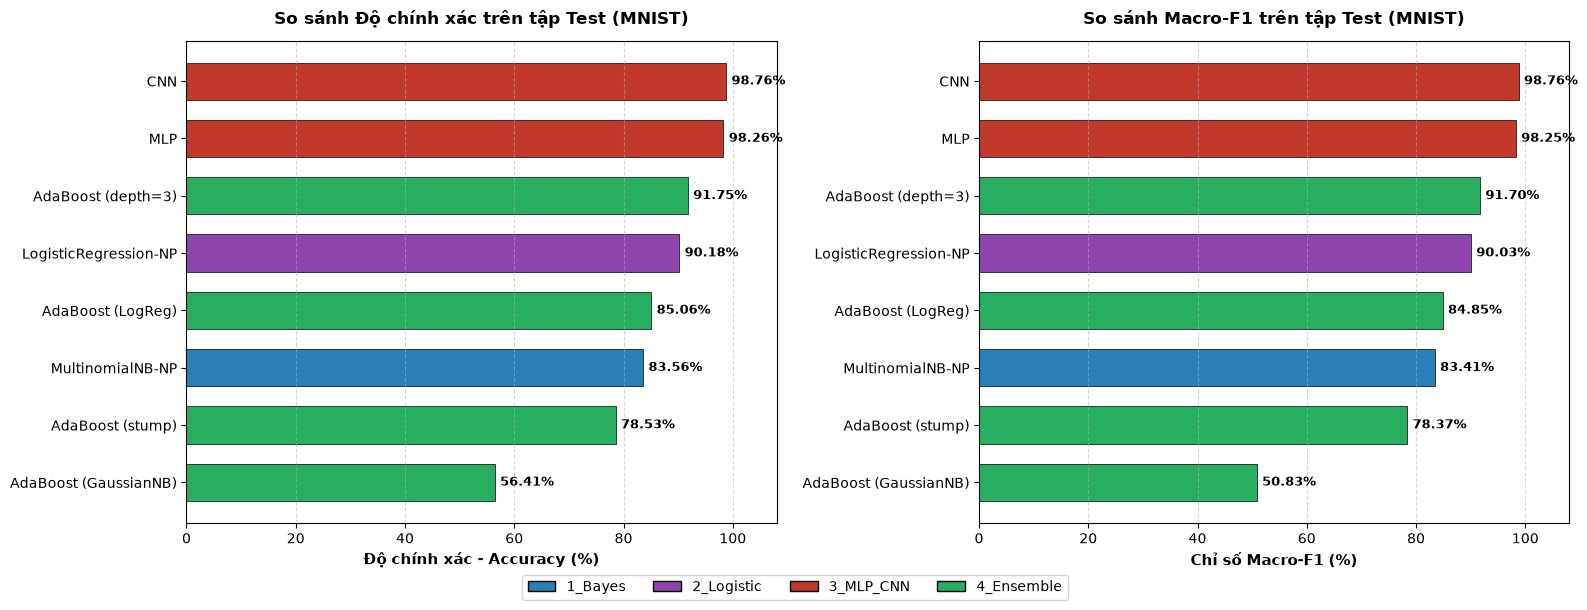

Đã tạo và lưu biểu đồ cột tại: C:\Users\Lenovo\Downloads\Pattern-Recognition\figures\Comp_01_accuracy_f1_comparison.png


In [42]:
# Biểu đồ cột nhóm so sánh Accuracy và Macro-F1

color_palette = {
    "1_Bayes": "#2980b9",      # Xanh dương
    "2_Logistic": "#8e44ad",   # Tím
    "3_MLP_CNN": "#c0392b",    # Đỏ gạch
    "4_Ensemble": "#27ae60"    # Xanh lá
}

model_names = test_df["model"].tolist()
acc_scores = (test_df["accuracy"] * 100).tolist()
f1_scores = (test_df["f1_macro"] * 100).tolist()
bar_colors = [color_palette[get_source_notebook(m)] for m in model_names]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Độ chính xác (Accuracy)
bars_acc = axes[0].barh(range(len(model_names)), acc_scores, color=bar_colors, edgecolor="black", linewidth=0.5, height=0.65)
axes[0].set_yticks(range(len(model_names)))
axes[0].set_yticklabels(model_names, fontsize=10, fontweight="medium")
axes[0].set_xlabel("Độ chính xác - Accuracy (%)", fontsize=11, fontweight="bold")
axes[0].set_title("So sánh Độ chính xác trên tập Test (MNIST)", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xlim(0, 108)
axes[0].invert_yaxis()
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

for bar, val in zip(bars_acc, acc_scores):
    axes[0].text(val + 1.0, bar.get_y() + bar.get_height()/2, f"{val:.2f}%", va="center", fontsize=9, fontweight="bold")

# Subplot 2: Macro-F1 Score
bars_f1 = axes[1].barh(range(len(model_names)), f1_scores, color=bar_colors, edgecolor="black", linewidth=0.5, height=0.65)
axes[1].set_yticks(range(len(model_names)))
axes[1].set_yticklabels(model_names, fontsize=10, fontweight="medium")
axes[1].set_xlabel("Chỉ số Macro-F1 (%)", fontsize=11, fontweight="bold")
axes[1].set_title("So sánh Macro-F1 trên tập Test (MNIST)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlim(0, 108)
axes[1].invert_yaxis()
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

for bar, val in zip(bars_f1, f1_scores):
    axes[1].text(val + 1.0, bar.get_y() + bar.get_height()/2, f"{val:.2f}%", va="center", fontsize=9, fontweight="bold")

# Thêm chú thích nhóm mô hình (Legend)
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=c, edgecolor="black", label=nb) for nb, c in color_palette.items()]
fig.legend(handles=legend_handles, loc="lower center", ncol=4, fontsize=10, bbox_to_anchor=(0.5, -0.02), frameon=True)

plt.tight_layout()
fig.subplots_adjust(bottom=0.12)

chart1_path = FIGURES_DIR / "Comp_01_accuracy_f1_comparison.png"
fig.savefig(chart1_path, dpi=150, bbox_inches="tight")

from IPython.display import display
display(fig)

print(f"Đã tạo và lưu biểu đồ cột tại: {chart1_path}")

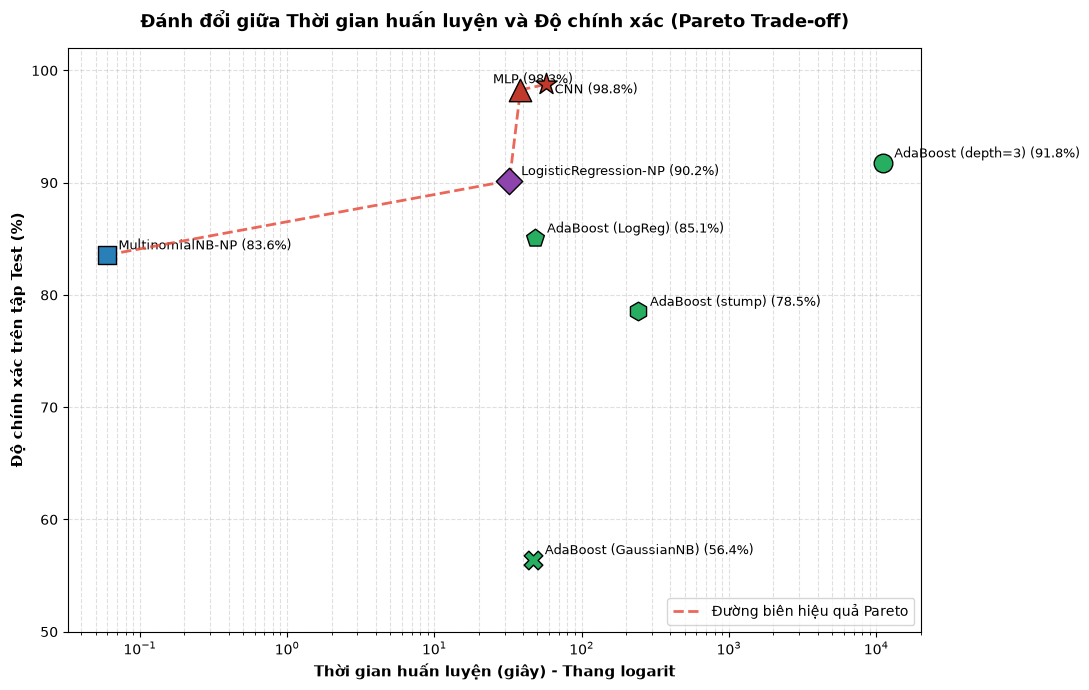

Đã tạo và lưu biểu đồ phân tán Pareto tại: C:\Users\Lenovo\Downloads\Pattern-Recognition\figures\Comp_02_time_vs_accuracy_pareto.png


In [43]:
from IPython.display import display

fig, ax = plt.subplots(figsize=(11, 7))

marker_dict = {
    "MultinomialNB-NP": "s",
    "LogisticRegression-NP": "D",
    "MLP": "^",
    "CNN": "*",
    "AdaBoost (depth=3)": "o",
    "AdaBoost (LogReg)": "p",
    "AdaBoost (stump)": "h",
    "AdaBoost (GaussianNB)": "X"
}

for _, row in test_df.iterrows():
    model = row["model"]
    color = color_palette[get_source_notebook(model)]
    marker = marker_dict.get(model, "o")
    train_time = row["train_seconds"]
    accuracy = row["accuracy"] * 100

    size = 260 if model in ["CNN", "MLP"] else 180
    ax.scatter(
        train_time, accuracy,
        color=color, marker=marker, s=size,
        edgecolors="black", linewidth=1.0, zorder=5
    )

    offset_y, offset_x = 0.5, 1.2
    if model == "CNN":
        offset_y, offset_x = -0.8, 1.15
    elif model == "MLP":
        offset_y, offset_x = 0.6, 0.65

    ax.annotate(
        f"{model} ({accuracy:.1f}%)",
        (train_time, accuracy),
        xytext=(train_time * offset_x, accuracy + offset_y),
        fontsize=9, fontweight="medium"
    )

# Vẽ đường biên Pareto
sorted_by_time = test_df.sort_values("train_seconds").reset_index(drop=True)
pareto_points = []
current_max_accuracy = -1.0

for _, row in sorted_by_time.iterrows():
    if row["accuracy"] > current_max_accuracy:
        pareto_points.append((row["train_seconds"], row["accuracy"] * 100))
        current_max_accuracy = row["accuracy"]

if len(pareto_points) > 1:
    px, py = zip(*pareto_points)
    ax.plot(
        px, py, linestyle="--", color="#e74c3c",
        linewidth=2.0, alpha=0.85,
        label="Đường biên hiệu quả Pareto", zorder=4
    )

ax.set_xscale("log")
ax.set_xlabel("Thời gian huấn luyện (giây) - Thang logarit", fontsize=11, fontweight="bold")
ax.set_ylabel("Độ chính xác trên tập Test (%)", fontsize=11, fontweight="bold")
ax.set_title(
    "Đánh đổi giữa Thời gian huấn luyện và Độ chính xác (Pareto Trade-off)",
    fontsize=13, fontweight="bold", pad=15
)
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.set_ylim(50, 102)
ax.legend(loc="lower right", fontsize=10, frameon=True)

plt.tight_layout()
chart2_path = FIGURES_DIR / "Comp_02_time_vs_accuracy_pareto.png"
fig.savefig(chart2_path, dpi=150, bbox_inches="tight")
display(fig)

print(f"Đã tạo và lưu biểu đồ phân tán Pareto tại: {chart2_path}")

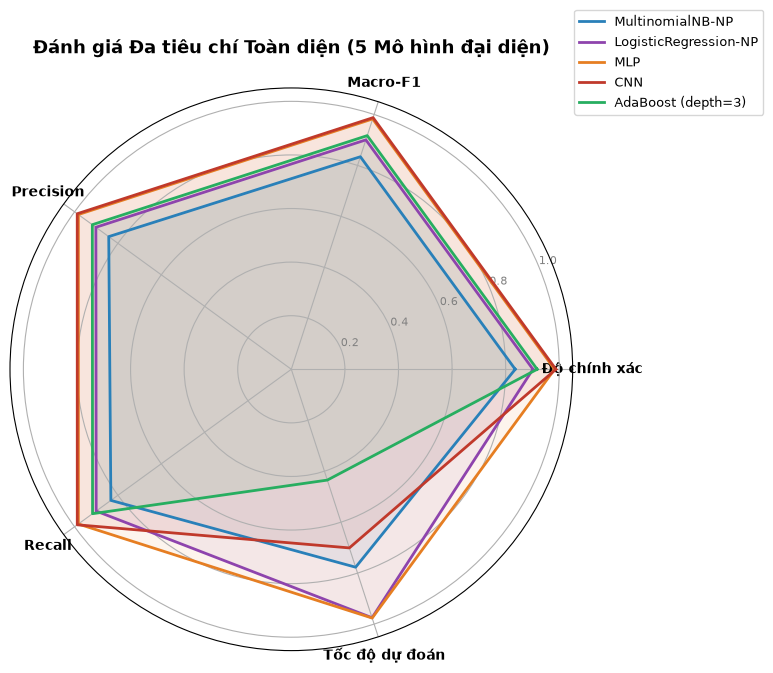

Đã tạo và lưu biểu đồ Radar tại: C:\Users\Lenovo\Downloads\Pattern-Recognition\figures\Comp_03_radar_multi_criteria.png


In [45]:
from math import pi
from IPython.display import display

# Chọn 5 mô hình đại diện
target_radar_models = [
    "MultinomialNB-NP",
    "LogisticRegression-NP",
    "MLP",
    "CNN",
    "AdaBoost (depth=3)"
]

radar_df = test_df[test_df["model"].isin(target_radar_models)].copy()
radar_df = radar_df.set_index("model").loc[target_radar_models]

categories = ["Độ chính xác", "Macro-F1", "Precision", "Recall", "Tốc độ dự đoán"]
num_vars = len(categories)

# Chuẩn hóa các tiêu chí về khoảng [0, 1]
radar_values = {}
for model in target_radar_models:
    row = radar_df.loc[model]
    speed_norm = 1.0 / (1.0 + np.log1p(row["predict_seconds"]))

    radar_values[model] = [
        row["accuracy"],
        row["f1_macro"],
        row["precision_macro"],
        row["recall_macro"],
        speed_norm
    ]

# Góc trên biểu đồ radar
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

model_radar_colors = {
    "MultinomialNB-NP": "#2980b9",
    "LogisticRegression-NP": "#8e44ad",
    "MLP": "#e67e22",
    "CNN": "#c0392b",
    "AdaBoost (depth=3)": "#27ae60"
}

for model in target_radar_models:
    values = radar_values[model] + [radar_values[model][0]]
    ax.plot(
        angles, values, linewidth=2.0,
        label=model, color=model_radar_colors[model]
    )
    ax.fill(angles, values, alpha=0.08, color=model_radar_colors[model])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10, fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=8, color="grey")
ax.set_title(
    "Đánh giá Đa tiêu chí Toàn diện (5 Mô hình đại diện)",
    fontsize=13, fontweight="bold", pad=25
)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=9, frameon=True)

plt.tight_layout()
chart3_path = FIGURES_DIR / "Comp_03_radar_multi_criteria.png"
fig.savefig(chart3_path, dpi=150, bbox_inches="tight")
display(fig)

print(f"Đã tạo và lưu biểu đồ Radar tại: {chart3_path}")


---
## **4.Kết luận và xếp hạng**

### **4.1. Xếp hạng dựa trên các tiêu chí**

#### **1. Mô hình nào đạt độ chính xác cao nhất?**
* **Mạng nơ-ron tích chập (`CNN`)** là mô hình có độ chính xác cao nhất tuyệt đối, đạt **98.76%** (chỉ phân loại sai 124 mẫu trên tổng số 10.000 mẫu kiểm thử), đi kèm điểm số Macro-F1 đạt **98.76%**.
* *Lý do vượt trội:* Khác với các phương pháp duỗi phẳng bức ảnh thành vector 1D, CNN bảo toàn hoàn toàn cấu trúc không gian 2 chiều ($28 \times 28$). Tầng tích chập với các bộ lọc cục bộ và cơ chế chia sẻ trọng số cho phép mạng học được các đặc trưng hình học cơ bản của nét chữ (đoạn thẳng, góc cong, điểm khép kín). Tầng Max-Pooling tạo ra tính bất biến đối với các phép dịch chuyển và co giãn nhẹ của chữ viết tay.
* Mô hình đứng thứ hai là `MLP` với độ chính xác **98.26%**, thua kém CNN 0.50% do việc kết nối toàn phần không có tính bất biến không gian và dễ bị ảnh hưởng khi nét chữ bị dịch chuyển vị trí.

#### **2. Mô hình nào hiệu quả nhất về thời gian huấn luyện?**
* **Xét về tốc độ thuần túy:** `MultinomialNB-NP` là mô hình nhanh nhất vô địch khi chỉ mất **0.06 giây** để huấn luyện trên 50.000 mẫu, nhanh gấp hơn 700 lần so với CNN.
* **Xét về tỷ suất hiệu năng trên chi phí (Hiệu quả tối ưu Pareto):** `MLP` là mô hình xuất sắc nhất. Chỉ mất **30.27 giây** huấn luyện trên CPU thông thường, MLP đã đạt tới **98.26%** độ chính xác.
* **Mô hình kém hiệu quả nhất:** `AdaBoost (depth=3)`. Tiêu tốn tới **11.019.24 giây** (hơn 3 giờ đồng hồ) nhưng chỉ đạt 91.75% độ chính xác. Tỷ lệ đánh đổi thời gian lấy độ chính xác của AdaBoost hoàn toàn không tương xứng khi so với các giải pháp mạng nơ-ron.

#### **3. Mô hình nào phù hợp nhất để triển khai thực tế (Real-time Deployment)?**
* **Đối với các thiết bị có tài nguyên phần cứng hạn chế (CPU yếu, bộ nhớ RAM thấp):**
  * `MLP` và `LogisticRegression-NP` là sự lựa chọn hàng đầu. Cả hai mô hình có độ trễ suy diễn cực thấp: **2.3 µs/mẫu** đối với MLP và **2.6 µs/mẫu** đối với Logistic Regression. Hệ thống có thể xử lý hơn 380.000 bức ảnh mỗi giây trên CPU đơn nhân tiêu chuẩn mà không cần bất kỳ bộ tăng tốc phần cứng nào.
* **Đối với các hệ thống nhận dạng yêu cầu độ chính xác tối đa:**
  * `CNN` là lựa chọn chuẩn mực. Với độ trễ **41.3 µs/mẫu** (~24.200 ảnh/giây), CNN hoàn toàn đáp ứng trơn tru các ứng dụng đọc số tài khoản ngân hàng, mã bưu chính hay số hóa biểu mẫu theo thời gian thực.
* **Lưu ý:** Các mô hình Boosting (`AdaBoost`) không phù hợp cho các dịch vụ đòi hỏi độ trễ thấp do cấu trúc phân loại tuần tự làm tăng độ trễ lên tới 266 - 784 µs cho mỗi mẫu.

---
### **4.2. Bảng tổng hợp xếp hạng và khuyến nghị áp dụng**

| Hạng | Mô hình | Accuracy | Train (s) | Độ trễ / mẫu | Ưu điểm chính | Hạn chế chính | Khuyến nghị áp dụng |
| :---: | :--- | :---: | :---: | :---: | :--- | :--- | :--- |
| **1** | **CNN** | **98.76%** | 43.6s | 41.3 µs | Chính xác nhất, giữ đặc trưng không gian 2D | Tốn tài nguyên hơn MLP | Ứng dụng thực tế cần độ chính xác tối đa |
| **2** | **MLP** | **98.26%** | 30.3s | **2.3 µs** | Suy diễn siêu tốc, độ chính xác rất cao | Thiếu tính bất biến vị trí | Thiết bị nhúng, IoT, luồng ảnh thời gian thực |
| **3** | **AdaBoost (depth=3)** | **91.75%** | 11019s | 266.8 µs | Bắt được tương tác phi tuyến bậc thấp | Train quá lâu (~3h), suy diễn chậm | Nghiên cứu lý thuyết học kết hợp |
| **4** | **Logistic Regression** | **90.18%** | 32.3s | 2.6 µs | Cực kỳ đơn giản, suy diễn nhanh | Chỉ phân tách được ranh giới tuyến tính | Baseline chuẩn cho phân loại tuyến tính |
| **5** | **AdaBoost (LogReg)** | **85.06%** | 48.4s | 30.1 µs | Train nhanh hơn cây quyết định | Kém hiệu quả hơn Logistic đơn lẻ | Không khuyến nghị sử dụng |
| **6** | **MultinomialNB** | **83.56%** | **0.06s** | 33.3 µs | Train tức thì (chỉ cần đếm tần suất) | Giả định độc lập sai lệch với dữ liệu ảnh | Thử nghiệm nhanh dữ liệu (Proof-of-Concept) |
| **7** | **AdaBoost (stump)** | **78.53%** | 242.0s | 242.0 µs | Cấu trúc cực đơn giản (cắt theo 1 pixel) | Quá yếu cho bài toán 10 chữ số | Minh họa bài giảng lý thuyết Boosting |
| **8** | **AdaBoost (GaussianNB)** | **56.41%** | 46.8s | 784.1 µs | - | Phân phối chuẩn xung đột với ảnh nhị phân | Không sử dụng |